In [ ]:
# Loading the Video
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = r'C:\Users\Jyotirmoy Nath\Downloads\Assignment1\umcp.mpg'


cap = cv2.VideoCapture(video_path)

frames = []
frame_ids = []

frame_idx = 0

# Extracting video properties
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frames.append(frame)
    frame_ids.append(frame_idx)
    frame_idx += 1

cap.release()

print("Total frames:", len(frames))
print(f"FPS: {fps}")
print(f"Resolution: {width}x{height}")
frames[10]

Total frames: 999
FPS: 29.97002997002997
Resolution: 352x240


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(240, 352, 3), dtype=uint8)

In [16]:
# Preprocessing
Resize_W = 128
Resize_H = 128

preprocessed_frames = []
for i, frame in enumerate(frames):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, (Resize_W, Resize_H))
    preprocessed_frames.append(resized)
print(f"Preprocessed {len(preprocessed_frames)} frames")
print(f"New shape: {preprocessed_frames[0].shape}")

Preprocessed 999 frames
New shape: (128, 128)


In [ ]:
# Frame Differences (Motion)
motion_frames = []
for i in range(len(preprocessed_frames) - 1):
    frame1 = preprocessed_frames[i].astype(np.float32)
    frame2 = preprocessed_frames[i + 1].astype(np.float32)
    diff = np.abs(frame2 - frame1)
    motion_frames.append(diff)

print(f" Computed {len(motion_frames)} motion frames")
avg_motion = [np.mean(m) for m in motion_frames]
print(f" Average motion: {np.mean(avg_motion):.2f}")
print(f" Max motion: {np.max(avg_motion):.2f}")



 Computed 998 motion frames
  Average motion: 1.67
  Max motion: 3.34


In [5]:
# Flatten motion frames into vectors
flattened_data = []
for motion in motion_frames:
    vector = motion.flatten()
    flattened_data.append(vector)

data_matrix = np.array(flattened_data)

print(f" Data matrix shape: {data_matrix.shape}")

 Data matrix shape: (998, 16384)


In [52]:
# Centering the data by subtracting the mean
mean_vector = np.mean(data_matrix, axis=0)
centered_data = data_matrix - mean_vector
print(f"Mean vector shape: {mean_vector.shape}")
print(f"Centered data shape: {centered_data.shape}")
print(f"Mean after centering: {np.mean(centered_data):.10f}")

Mean vector shape: (16384,)
Centered data shape: (998, 16384)
Mean after centering: 0.0000000000


In [53]:
# Compute the covariance matrix 
n_samples = centered_data.shape[0]
covariance_matrix = (centered_data.T @ centered_data) / (n_samples - 1)
print(f"Covariance shape: {covariance_matrix.shape}")
print(f"Symmetric: {np.allclose(covariance_matrix, covariance_matrix.T)}")


Covariance shape: (16384, 16384)
Symmetric: True


In [17]:
#Eigen Decomposition
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

# Sort descending
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print(f"Computed {len(eigenvalues)} eigenvalues")
print(f"Top 10 eigenvalues:")
for i in range(10):
    var_ratio = eigenvalues[i] / np.sum(eigenvalues) * 100
    print(f"λ_{i+1:2d} = {eigenvalues[i]:10.2f}  ({var_ratio:5.2f}%)")

# Cumulative variance
cumvar = np.cumsum(eigenvalues) / np.sum(eigenvalues)
print(f"\nCumulative variance:")
for thresh in [0.5, 0.7, 0.9, 0.95]:
    k = np.argmax(cumvar >= thresh) + 1
    print(f"{thresh*100:.0f}%: {k} components")


Computed 16384 eigenvalues
Top 10 eigenvalues:
λ_ 1 =   18999.50  ( 5.86%)
λ_ 2 =   10889.28  ( 3.36%)
λ_ 3 =    8176.87  ( 2.52%)
λ_ 4 =    5687.32  ( 1.75%)
λ_ 5 =    4444.58  ( 1.37%)
λ_ 6 =    4138.84  ( 1.28%)
λ_ 7 =    4033.84  ( 1.24%)
λ_ 8 =    3930.85  ( 1.21%)
λ_ 9 =    3707.71  ( 1.14%)
λ_10 =    3281.23  ( 1.01%)

Cumulative variance:
50%: 69 components
70%: 173 components
90%: 440 components
95%: 596 components


In [54]:
# Key Component Selection of PCA

# Variance threshold Method
VARIANCE_THRESHOLD = 0.95
auto_k = np.argmax(cumvar >= VARIANCE_THRESHOLD) + 1
print(f"Auto k (95% variance): {auto_k}")
print(f"Variance explained: {cumvar[auto_k-1]*100:.2f}%")
print(f"Reduction: {len(eigenvalues)}/{auto_k} = {len(eigenvalues)/auto_k:.1f}x")

# Fixed k selection
k = 100  
selected_eigenvalues = eigenvalues[:k]
selected_eigenvectors = eigenvectors[:, :k]

print(f"Selected k={k} components")
print(f"  Variance explained: {np.sum(selected_eigenvalues)/np.sum(eigenvalues)*100:.2f}%")
print(f"  Reduction: {len(eigenvalues)} → {k} ({len(eigenvalues)/k:.1f}x)")

Auto k (95% variance): 596
Variance explained: 95.02%
Reduction: 16384/596 = 27.5x
Selected k=100 components
  Variance explained: 57.88%
  Reduction: 16384 → 100 (163.8x)


In [55]:
# Projecting to PCA Space
pca_projections = centered_data @ selected_eigenvectors
print(f"Original: {centered_data.shape}")
print(f"Projected: {pca_projections.shape}")
print(f"Reduction: {centered_data.shape[1]/pca_projections.shape[1]:.1f}x")
# Verify reconstruction
reconstructed = pca_projections @ selected_eigenvectors.T + mean_vector
recon_error = np.sqrt(np.mean((data_matrix - reconstructed)**2))
print(f" Reconstruction RMSE: {recon_error:.4f}")



Original: (998, 16384)
Projected: (998, 100)
Reduction: 163.8x
 Reconstruction RMSE: 2.8857


In [59]:
# Frame Scoring
weighted = pca_projections**2 * selected_eigenvalues
frame_scores = np.sum(weighted, axis=1)

# Normalize to [0, 1]
frame_scores = (frame_scores - frame_scores.min()) / (frame_scores.max() - frame_scores.min())

print(f"Scores computed and normalized")
print(f"Range: [{frame_scores.min():.4f}, {frame_scores.max():.4f}]")
print(f"Mean: {frame_scores.mean():.4f}")
print(f"Std: {frame_scores.std():.4f}")

highest_idx = np.argmax(frame_scores)
lowest_idx = np.argmin(frame_scores)
print(f"Highest: Frame {highest_idx}, score={frame_scores[highest_idx]:.4f}")
print(f"Lowest: Frame {lowest_idx}, score={frame_scores[lowest_idx]:.4f}")

# Analyze distribution
percentiles = [50, 75, 90, 95, 99]
print(f"Score Percentiles:")
for p in percentiles:
    val = np.percentile(frame_scores, p)
    print(f"{p}th percentile: {val:.4f}")

Scores computed and normalized
Range: [0.0000, 1.0000]
Mean: 0.0601
Std: 0.1505
Highest: Frame 273, score=1.0000
Lowest: Frame 885, score=0.0000
Score Percentiles:
50th percentile: 0.0144
75th percentile: 0.0280
90th percentile: 0.1107
95th percentile: 0.2883
99th percentile: 0.8267


In [63]:
# Select keyframes

N_KEYFRAMES = 20
MIN_GAP = 20

print(f"\nOptimized Parameters:")
print(f"  Number of keyframes: {N_KEYFRAMES}")
print(f"  Minimum gap: {MIN_GAP} frames")
print(f"  Expected coverage: {N_KEYFRAMES * MIN_GAP / len(frames) * 100:.1f}% minimum")

keyframe_diff_idx = []
remaining = frame_scores.copy()

for i in range(N_KEYFRAMES):
    best = np.argmax(remaining)
    keyframe_diff_idx.append(best)
    
    start = max(0, best - MIN_GAP)
    end = min(len(remaining), best + MIN_GAP + 1)
    remaining[start:end] = -1
    
    print(f"  KF{i+1:2d}: Frame {best:3d}, Score={frame_scores[best]:.4f}")

keyframe_diff_idx.sort()
keyframe_indices = [idx + 1 for idx in keyframe_diff_idx]

print(f"selected {len(keyframe_indices)} keyframes")
print(f"Frame indices: {keyframe_indices[:10]}... (showing first 10)")

gaps = np.diff(keyframe_indices)
print(f"Average gap: {np.mean(gaps):.1f} frames ({np.mean(gaps)/fps:.2f}s)")
print(f"Min gap: {np.min(gaps)} frames")
print(f"Max gap: {np.max(gaps)} frames")
print(f"Coverage: {(keyframe_indices[-1]-keyframe_indices[0])/len(frames)*100:.1f}% of video")
print(f"Compression ratio: {len(frames)/len(keyframe_indices):.1f}x")



Optimized Parameters:
  Number of keyframes: 20
  Minimum gap: 20 frames
  Expected coverage: 40.0% minimum
  KF 1: Frame 273, Score=1.0000
  KF 2: Frame  99, Score=0.8716
  KF 3: Frame 252, Score=0.6651
  KF 4: Frame 294, Score=0.2521
  KF 5: Frame 230, Score=0.1291
  KF 6: Frame 123, Score=0.1024
  KF 7: Frame  72, Score=0.0946
  KF 8: Frame  49, Score=0.0657
  KF 9: Frame 144, Score=0.0542
  KF10: Frame 486, Score=0.0396
  KF11: Frame 448, Score=0.0373
  KF12: Frame  28, Score=0.0367
  KF13: Frame 696, Score=0.0334
  KF14: Frame 772, Score=0.0279
  KF15: Frame 507, Score=0.0266
  KF16: Frame 166, Score=0.0237
  KF17: Frame 351, Score=0.0237
  KF18: Frame 422, Score=0.0211
  KF19: Frame 383, Score=0.0207
  KF20: Frame 531, Score=0.0206
selected 20 keyframes
Frame indices: [np.int64(29), np.int64(50), np.int64(73), np.int64(100), np.int64(124), np.int64(145), np.int64(167), np.int64(231), np.int64(253), np.int64(274)]... (showing first 10)
Average gap: 39.2 frames (1.31s)
Min gap: 21

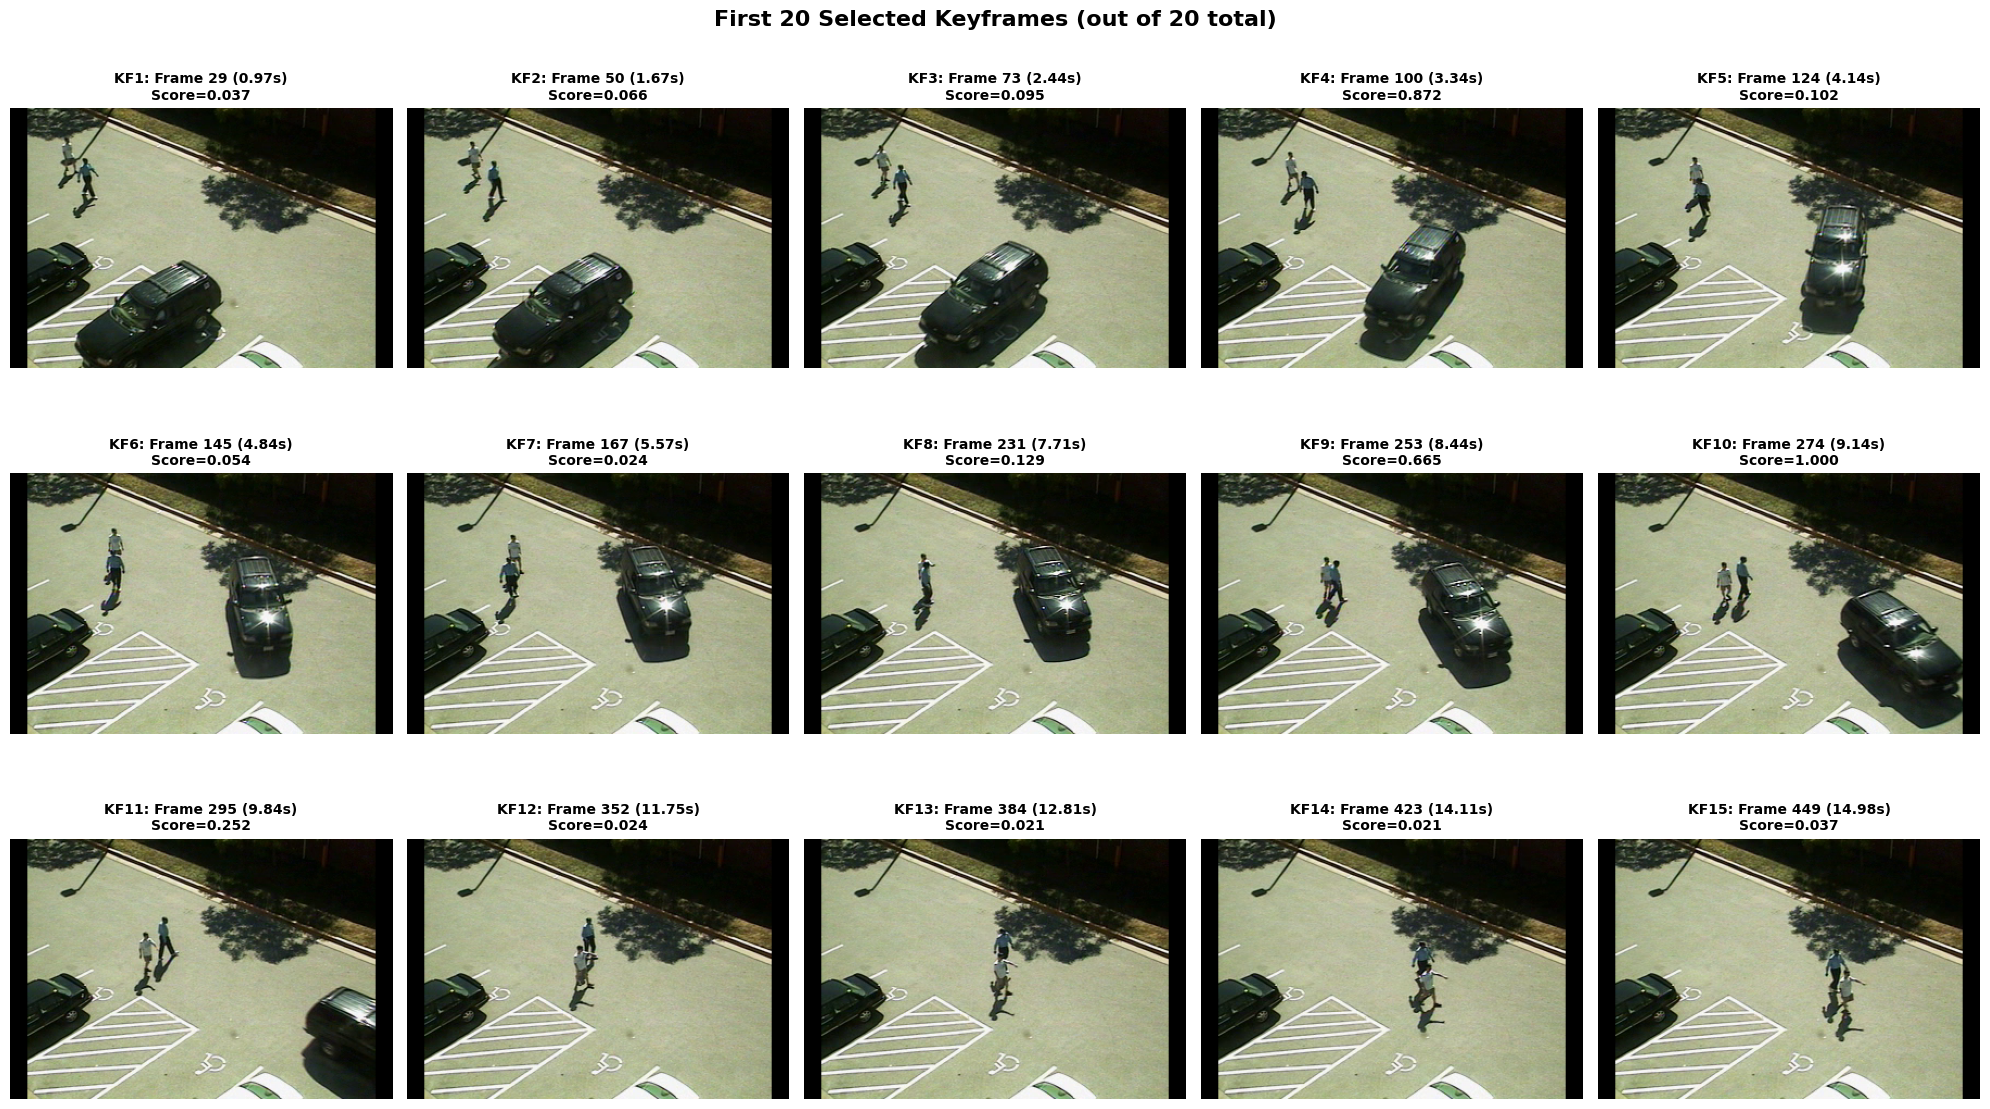

In [64]:
# SHOW KEYFRAMES - OPTIMIZED

n_show = min(20, len(keyframe_indices))
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()

for i in range(15):
    if i < n_show:
        idx = keyframe_indices[i]
        axes[i].imshow(cv2.cvtColor(frames[idx], cv2.COLOR_BGR2RGB))
        axes[i].set_title(f'KF{i+1}: Frame {idx} ({idx/fps:.2f}s)\nScore={frame_scores[idx-1]:.3f}', 
                          fontsize=10, fontweight='bold')
        axes[i].axis('off')
    else:
        axes[i].axis('off')

plt.suptitle(f'First {n_show} Selected Keyframes (out of {len(keyframe_indices)} total)', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# Creating Summary Video
output_path = r"C:\Users\Jyotirmoy Nath\Downloads\Assignment1\video_summary.MP4"
height, width = frames[0].shape[:2]

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, 2, (width, height))

for idx in keyframe_indices:
    out.write(frames[idx])

out.release()

print(f"Summary video created: {output_path}")
print(f"Original: {len(frames)} frames, {len(frames)/fps:.1f}s")
print(f"Summary: {len(keyframe_indices)} frames, {len(keyframe_indices)/2:.1f}s")
print(f"Compression: {len(frames)/len(keyframe_indices):.1f}x")

✓ Summary video created: C:\Users\Jyotirmoy Nath\Downloads\Assignment1\video_summary.MP4
  Original: 999 frames, 33.3s
  Summary: 20 frames, 10.0s
  Compression: 50.0x


In [71]:
print("="*80)
print("QUESTION 1: EXPERIMENTATION WITH DIFFERENT NUMBER OF KEYFRAMES")
print("="*80)

# Test different numbers of keyframes
keyframe_counts = [5, 10, 15, 20, 25, 30, 40, 50]
MIN_GAP = 15  # Keep gap constant for fair comparison

keyframe_experiments = {}

for n_kf in keyframe_counts:
    print(f"\n{'='*80}")
    print(f"Experiment: N_KEYFRAMES = {n_kf}")
    print(f"{'='*80}")
    
    # Select keyframes using greedy algorithm with suppression
    selected_kf_idx = []
    remaining_scores = frame_scores.copy()
    
    for i in range(n_kf):
        # Check if any frames left with positive scores
        if np.max(remaining_scores) < 0:
            print(f"  Warning: Only {len(selected_kf_idx)} keyframes selected (ran out of frames)")
            break
        
        # Find best frame
        best_idx = np.argmax(remaining_scores)
        selected_kf_idx.append(best_idx)
        
        # Suppress nearby frames
        start = max(0, best_idx - MIN_GAP)
        end = min(len(remaining_scores), best_idx + MIN_GAP + 1)
        remaining_scores[start:end] = -1
    
    # Sort by temporal order
    selected_kf_idx.sort()
    selected_kf_original = [idx + 1 for idx in selected_kf_idx]
    
    # Compute evaluation metrics
    if len(selected_kf_idx) > 0:
        # Score statistics
        kf_scores = [frame_scores[idx] for idx in selected_kf_idx]
        avg_score = np.mean(kf_scores)
        min_score = np.min(kf_scores)
        max_score = np.max(kf_scores)
        std_score = np.std(kf_scores)
        
        # Temporal metrics
        if len(selected_kf_original) > 1:
            gaps = np.diff(selected_kf_original)
            avg_gap = np.mean(gaps)
            std_gap = np.std(gaps)
            min_gap = np.min(gaps)
            max_gap = np.max(gaps)
            coverage = (selected_kf_original[-1] - selected_kf_original[0]) / len(frames) * 100
        else:
            avg_gap = std_gap = min_gap = max_gap = 0
            coverage = 0
        
        # Compression metrics
        compression_ratio = len(frames) / len(selected_kf_idx)
        summary_duration = len(selected_kf_idx) / 2.0  # At 2 FPS
        original_duration = len(frames) / fps
        time_reduction = (1 - summary_duration / original_duration) * 100
        
        # Store results
        keyframe_experiments[n_kf] = {
            'keyframes': selected_kf_original,
            'num_selected': len(selected_kf_idx),
            'avg_score': avg_score,
            'min_score': min_score,
            'max_score': max_score,
            'std_score': std_score,
            'avg_gap': avg_gap,
            'std_gap': std_gap,
            'min_gap': min_gap,
            'max_gap': max_gap,
            'coverage': coverage,
            'compression_ratio': compression_ratio,
            'summary_duration': summary_duration,
            'time_reduction': time_reduction
        }
        
        # Print results
        print(f"Results:")
        print(f"  Keyframes selected: {len(selected_kf_idx)}")
        print(f"  Average score: {avg_score:.4f} (range: [{min_score:.4f}, {max_score:.4f}])")
        print(f"  Score std dev: {std_score:.4f}")
        print(f"  Average gap: {avg_gap:.1f} frames ({avg_gap/fps:.2f}s)")
        print(f"  Gap range: [{min_gap}, {max_gap}] frames")
        print(f"  Temporal coverage: {coverage:.1f}%")
        print(f"  Compression ratio: {compression_ratio:.1f}x")
        print(f"  Summary duration: {summary_duration:.1f}s (vs {original_duration:.1f}s original)")
        print(f"  Time reduction: {time_reduction:.1f}%")

# Print comprehensive comparison table
print("\n" + "="*80)
print("COMPREHENSIVE COMPARISON TABLE")
print("="*80)
print(f"{'N_KF':<6} {'Actual':<8} {'Avg Score':<11} {'Coverage%':<11} {'Compress':<10} {'Gap':<10} {'Duration':<10}")
print("-"*80)
for n_kf in keyframe_counts:
    if n_kf in keyframe_experiments:
        r = keyframe_experiments[n_kf]
        print(f"{n_kf:<6} {r['num_selected']:<8} {r['avg_score']:<11.4f} {r['coverage']:<11.1f} "
              f"{r['compression_ratio']:<10.1f}x {r['avg_gap']:<10.1f} {r['summary_duration']:<10.1f}s")

print("\n✓ Experimentation complete!")

QUESTION 1: EXPERIMENTATION WITH DIFFERENT NUMBER OF KEYFRAMES

Experiment: N_KEYFRAMES = 5
Results:
  Keyframes selected: 5
  Average score: 0.6319 (range: [0.2197, 1.0000])
  Score std dev: 0.2964
  Average gap: 47.5 frames (1.58s)
  Gap range: [16, 136] frames
  Temporal coverage: 19.0%
  Compression ratio: 199.8x
  Summary duration: 2.5s (vs 33.3s original)
  Time reduction: 92.5%

Experiment: N_KEYFRAMES = 10
Results:
  Keyframes selected: 10
  Average score: 0.3679 (range: [0.0664, 1.0000])
  Score std dev: 0.3376
  Average gap: 27.8 frames (0.93s)
  Gap range: [16, 99] frames
  Temporal coverage: 25.0%
  Compression ratio: 99.9x
  Summary duration: 5.0s (vs 33.3s original)
  Time reduction: 85.0%

Experiment: N_KEYFRAMES = 15
Results:
  Keyframes selected: 15
  Average score: 0.2583 (range: [0.0333, 1.0000])
  Score std dev: 0.3163
  Average gap: 48.1 frames (1.61s)
  Gap range: [16, 210] frames
  Temporal coverage: 67.5%
  Compression ratio: 66.6x
  Summary duration: 7.5s (vs 3

C:\Users\Jyotirmoy Nath\AppData\Local\Temp\ipykernel_8884\20927639.py:65: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax5.boxplot(score_distributions, labels=box_labels, patch_artist=True)
C:\Users\Jyotirmoy Nath\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


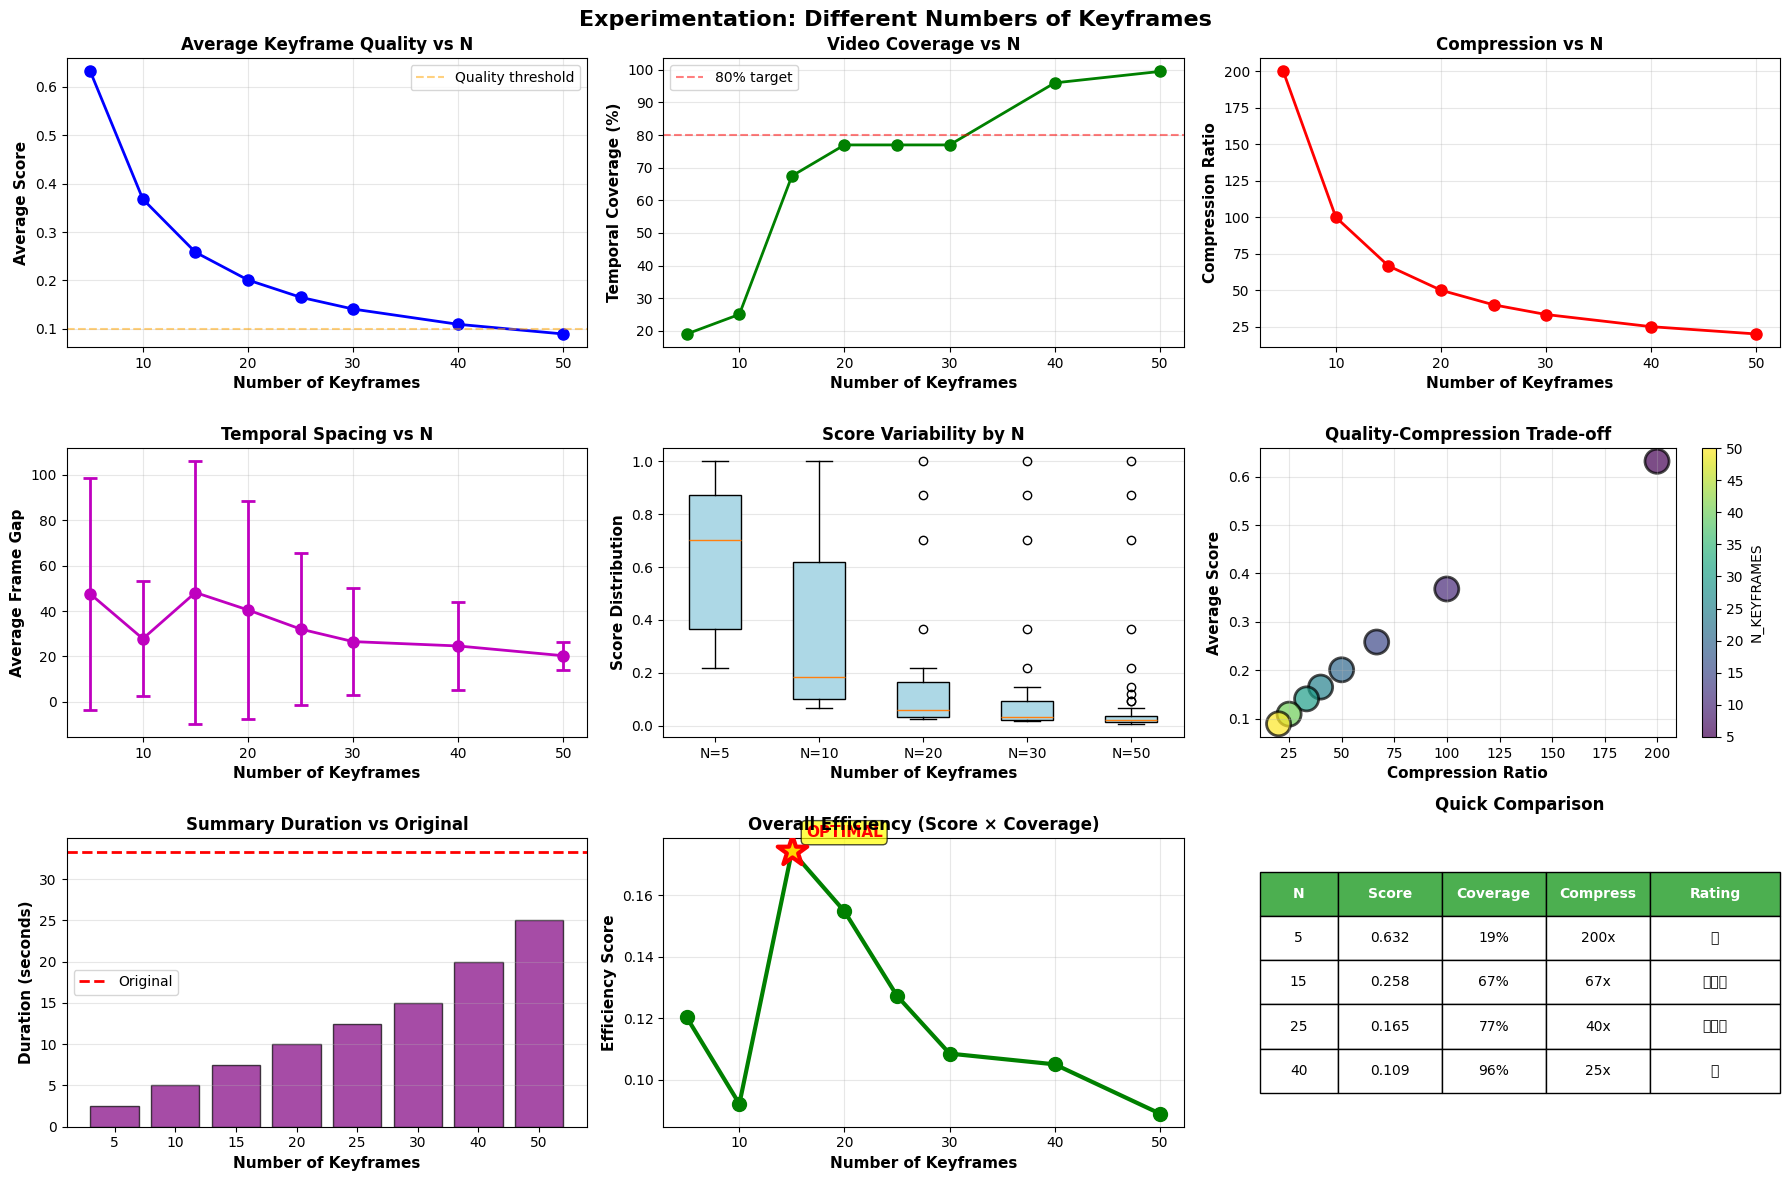

In [72]:

# ============================================================================
# CELL 2: VISUALIZE EXPERIMENTATION RESULTS
# ============================================================================

from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(18, 12))
gs = GridSpec(3, 3, figure=fig)

n_kf_list = sorted(keyframe_experiments.keys())

# 1. Average Score vs N_KEYFRAMES
ax1 = fig.add_subplot(gs[0, 0])
avg_scores = [keyframe_experiments[n]['avg_score'] for n in n_kf_list]
ax1.plot(n_kf_list, avg_scores, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax1.set_ylabel('Average Score', fontweight='bold', fontsize=11)
ax1.set_title('Average Keyframe Quality vs N', fontweight='bold', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.axhline(y=0.1, color='orange', linestyle='--', alpha=0.5, label='Quality threshold')
ax1.legend()

# 2. Coverage vs N_KEYFRAMES
ax2 = fig.add_subplot(gs[0, 1])
coverages = [keyframe_experiments[n]['coverage'] for n in n_kf_list]
ax2.plot(n_kf_list, coverages, 'go-', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax2.set_ylabel('Temporal Coverage (%)', fontweight='bold', fontsize=11)
ax2.set_title('Video Coverage vs N', fontweight='bold', fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.axhline(y=80, color='red', linestyle='--', alpha=0.5, label='80% target')
ax2.legend()

# 3. Compression Ratio vs N_KEYFRAMES
ax3 = fig.add_subplot(gs[0, 2])
compressions = [keyframe_experiments[n]['compression_ratio'] for n in n_kf_list]
ax3.plot(n_kf_list, compressions, 'ro-', linewidth=2, markersize=8)
ax3.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax3.set_ylabel('Compression Ratio', fontweight='bold', fontsize=11)
ax3.set_title('Compression vs N', fontweight='bold', fontsize=12)
ax3.grid(True, alpha=0.3)

# 4. Gap statistics
ax4 = fig.add_subplot(gs[1, 0])
avg_gaps = [keyframe_experiments[n]['avg_gap'] for n in n_kf_list]
std_gaps = [keyframe_experiments[n]['std_gap'] for n in n_kf_list]
ax4.errorbar(n_kf_list, avg_gaps, yerr=std_gaps, fmt='mo-', 
            linewidth=2, markersize=8, capsize=5, capthick=2)
ax4.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax4.set_ylabel('Average Frame Gap', fontweight='bold', fontsize=11)
ax4.set_title('Temporal Spacing vs N', fontweight='bold', fontsize=12)
ax4.grid(True, alpha=0.3)

# 5. Score distribution boxplot
ax5 = fig.add_subplot(gs[1, 1])
score_distributions = []
box_labels = []
for n_kf in [5, 10, 20, 30, 50]:
    if n_kf in keyframe_experiments:
        kf_indices = [idx - 1 for idx in keyframe_experiments[n_kf]['keyframes']]
        scores = [frame_scores[idx] for idx in kf_indices]
        score_distributions.append(scores)
        box_labels.append(f'N={n_kf}')

bp = ax5.boxplot(score_distributions, labels=box_labels, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
ax5.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax5.set_ylabel('Score Distribution', fontweight='bold', fontsize=11)
ax5.set_title('Score Variability by N', fontweight='bold', fontsize=12)
ax5.grid(True, alpha=0.3, axis='y')

# 6. Quality vs Compression Trade-off
ax6 = fig.add_subplot(gs[1, 2])
scatter = ax6.scatter(compressions, avg_scores, s=300, c=n_kf_list, 
                     cmap='viridis', alpha=0.7, edgecolors='black', linewidths=2)
for n_kf, comp, score in zip(n_kf_list, compressions, avg_scores):
    ax6.annotate(f'{n_kf}', xy=(comp, score), xytext=(0, 0),
                ha='center', va='center', fontsize=10, fontweight='bold', color='white')
ax6.set_xlabel('Compression Ratio', fontweight='bold', fontsize=11)
ax6.set_ylabel('Average Score', fontweight='bold', fontsize=11)
ax6.set_title('Quality-Compression Trade-off', fontweight='bold', fontsize=12)
ax6.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax6, label='N_KEYFRAMES')

# 7. Summary duration comparison
ax7 = fig.add_subplot(gs[2, 0])
durations = [keyframe_experiments[n]['summary_duration'] for n in n_kf_list]
ax7.bar(range(len(n_kf_list)), durations, color='purple', alpha=0.7, edgecolor='black')
ax7.set_xticks(range(len(n_kf_list)))
ax7.set_xticklabels([f'{n}' for n in n_kf_list])
ax7.axhline(y=len(frames)/fps, color='red', linestyle='--', linewidth=2, label='Original')
ax7.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax7.set_ylabel('Duration (seconds)', fontweight='bold', fontsize=11)
ax7.set_title('Summary Duration vs Original', fontweight='bold', fontsize=12)
ax7.legend()
ax7.grid(True, alpha=0.3, axis='y')

# 8. Efficiency metric (Score × Coverage)
ax8 = fig.add_subplot(gs[2, 1])
efficiency = [keyframe_experiments[n]['avg_score'] * keyframe_experiments[n]['coverage'] / 100 
              for n in n_kf_list]
ax8.plot(n_kf_list, efficiency, 'go-', linewidth=3, markersize=10)
best_idx = np.argmax(efficiency)
ax8.scatter([n_kf_list[best_idx]], [efficiency[best_idx]], 
           s=500, c='gold', marker='*', edgecolors='red', linewidths=3, zorder=10)
ax8.annotate('OPTIMAL', xy=(n_kf_list[best_idx], efficiency[best_idx]), 
            xytext=(10, 10), textcoords='offset points',
            fontsize=11, fontweight='bold', color='red',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))
ax8.set_xlabel('Number of Keyframes', fontweight='bold', fontsize=11)
ax8.set_ylabel('Efficiency Score', fontweight='bold', fontsize=11)
ax8.set_title('Overall Efficiency (Score × Coverage)', fontweight='bold', fontsize=12)
ax8.grid(True, alpha=0.3)

# 9. Comparison table
ax9 = fig.add_subplot(gs[2, 2])
ax9.axis('off')
table_data = [['N', 'Score', 'Coverage', 'Compress', 'Rating']]
for n_kf in [5, 15, 25, 40]:
    if n_kf in keyframe_experiments:
        r = keyframe_experiments[n_kf]
        rating = '⭐⭐⭐' if 15 <= n_kf <= 25 else '⭐⭐' if 10 <= n_kf <= 30 else '⭐'
        table_data.append([
            str(n_kf),
            f"{r['avg_score']:.3f}",
            f"{r['coverage']:.0f}%",
            f"{r['compression_ratio']:.0f}x",
            rating
        ])

table = ax9.table(cellText=table_data, cellLoc='center', loc='center',
                 colWidths=[0.15, 0.2, 0.2, 0.2, 0.25])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.5)

# Style header
for i in range(5):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')

ax9.set_title('Quick Comparison', fontweight='bold', fontsize=12, pad=20)

plt.suptitle('Experimentation: Different Numbers of Keyframes', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [73]:
print("\n" + "="*80)
print("QUESTION 2: SELECTING OPTIMAL NUMBER OF KEYFRAMES")
print("="*80)

# Method 1: Coverage-Based Selection
def method1_coverage_based(target_coverage=80):
    """Select N to achieve target temporal coverage."""
    for n_kf in sorted(keyframe_experiments.keys()):
        if keyframe_experiments[n_kf]['coverage'] >= target_coverage:
            return n_kf
    return max(keyframe_experiments.keys())

optimal_n_coverage = method1_coverage_based(80)
print(f"\n1. COVERAGE-BASED METHOD (Target: 80% coverage)")
print(f"   Optimal N_KEYFRAMES: {optimal_n_coverage}")
print(f"   Actual coverage: {keyframe_experiments[optimal_n_coverage]['coverage']:.1f}%")
print(f"   Rationale: Ensures keyframes span at least 80% of video timeline")

# Method 2: Compression-Based Selection
def method2_compression_based(target_compression=30):
    """Select N to achieve target compression ratio."""
    best_n = 20
    best_diff = float('inf')
    for n_kf, result in keyframe_experiments.items():
        diff = abs(result['compression_ratio'] - target_compression)
        if diff < best_diff:
            best_diff = diff
            best_n = n_kf
    return best_n

optimal_n_compression = method2_compression_based(30)
print(f"\n2. COMPRESSION-BASED METHOD (Target: 30x compression)")
print(f"   Optimal N_KEYFRAMES: {optimal_n_compression}")
print(f"   Actual compression: {keyframe_experiments[optimal_n_compression]['compression_ratio']:.1f}x")
print(f"   Rationale: Balances summary length with information retention")

# Method 3: Elbow Method (Diminishing Returns)
def method3_elbow_method():
    """Find elbow point where score improvement diminishes."""
    n_list = sorted(keyframe_experiments.keys())
    scores = [keyframe_experiments[n]['avg_score'] for n in n_list]
    
    # Compute second derivative (rate of change of rate of change)
    if len(scores) >= 3:
        first_deriv = np.diff(scores)
        second_deriv = np.diff(first_deriv)
        
        # Find maximum curvature (elbow)
        elbow_idx = np.argmin(second_deriv) + 2  # +2 due to double diff
        if elbow_idx < len(n_list):
            return n_list[elbow_idx]
    
    return 20  # Default

optimal_n_elbow = method3_elbow_method()
print(f"\n3. ELBOW METHOD (Diminishing returns)")
print(f"   Optimal N_KEYFRAMES: {optimal_n_elbow}")
print(f"   Average score: {keyframe_experiments[optimal_n_elbow]['avg_score']:.4f}")
print(f"   Rationale: Beyond this point, adding frames yields little score improvement")

# Method 4: Duration-Based (Rule of Thumb)
def method4_duration_based(frames_per_segment=2):
    """Rule of thumb: 1 keyframe every 2-3 seconds."""
    video_duration = len(frames) / fps
    optimal_n = int(video_duration / frames_per_segment)
    
    # Find closest in experiments
    best_n = min(keyframe_experiments.keys(), 
                 key=lambda x: abs(x - optimal_n))
    return best_n

optimal_n_duration = method4_duration_based(2)
print(f"\n4. DURATION-BASED METHOD (1 keyframe per 2 seconds)")
print(f"   Optimal N_KEYFRAMES: {optimal_n_duration}")
print(f"   Video duration: {len(frames)/fps:.1f}s")
print(f"   Rationale: Regular temporal sampling for comprehensive coverage")

# Method 5: Score Threshold
def method5_score_threshold(percentile=90):
    """Select N that captures frames above percentile threshold."""
    threshold = np.percentile(frame_scores, percentile)
    high_score_count = np.sum(frame_scores >= threshold)
    
    # Account for MIN_GAP suppression (rough estimate)
    estimated_n = int(high_score_count * 0.4)  # ~40% survive after suppression
    
    # Find closest in experiments
    best_n = min(keyframe_experiments.keys(), 
                 key=lambda x: abs(x - estimated_n))
    return best_n

optimal_n_threshold = method5_score_threshold(90)
print(f"\n5. SCORE THRESHOLD METHOD (90th percentile)")
print(f"   Optimal N_KEYFRAMES: {optimal_n_threshold}")
print(f"   Threshold score: {np.percentile(frame_scores, 90):.4f}")
print(f"   Rationale: Selects only high-quality frames above threshold")

# Method 6: Combined/Weighted Score (RECOMMENDED)
def method6_combined_scoring():
    """Combined metric balancing multiple factors."""
    best_n = 20
    best_combined = -float('inf')
    
    # Weights (adjust based on priorities)
    w_quality = 0.4    # Keyframe quality
    w_coverage = 0.3   # Temporal coverage
    w_efficiency = 0.3  # Compression efficiency
    
    for n_kf, result in keyframe_experiments.items():
        # Normalize all metrics to [0, 1]
        norm_quality = result['avg_score']  # Already [0, 1]
        norm_coverage = result['coverage'] / 100.0
        norm_efficiency = 1.0 / (1.0 + result['compression_ratio'] / 50.0)
        
        combined = (w_quality * norm_quality + 
                   w_coverage * norm_coverage + 
                   w_efficiency * norm_efficiency)
        
        if combined > best_combined:
            best_combined = combined
            best_n = n_kf
    
    return best_n, best_combined

optimal_n_combined, combined_score = method6_combined_scoring()
print(f"\n6. COMBINED SCORING METHOD (Weighted multi-criteria) ⭐ RECOMMENDED")
print(f"   Optimal N_KEYFRAMES: {optimal_n_combined}")
print(f"   Combined score: {combined_score:.4f}")
print(f"   Weights: Quality=40%, Coverage=30%, Efficiency=30%")
print(f"   Rationale: Balances all important factors simultaneously")

# Summary of all methods
print("\n" + "="*80)
print("SUMMARY: ALL METHODS")
print("="*80)
print(f"{'Method':<35} {'Optimal N':<12} {'Score':<10} {'Coverage':<12} {'Compress':<10}")
print("-"*80)

methods = [
    ("1. Coverage-based (80%)", optimal_n_coverage),
    ("2. Compression-based (30x)", optimal_n_compression),
    ("3. Elbow method", optimal_n_elbow),
    ("4. Duration-based (1 per 2s)", optimal_n_duration),
    ("5. Score threshold (90th %)", optimal_n_threshold),
    ("6. Combined scoring ⭐", optimal_n_combined)
]

for method_name, n in methods:
    r = keyframe_experiments[n]
    marker = " ✓" if n == optimal_n_combined else ""
    print(f"{method_name:<35} {n:<12} {r['avg_score']:<10.4f} {r['coverage']:<12.1f}% {r['compression_ratio']:<10.1f}x{marker}")

print("\n" + "="*80)
print(f"FINAL RECOMMENDATION: {optimal_n_combined} keyframes")
print(f"  - Balances quality ({keyframe_experiments[optimal_n_combined]['avg_score']:.4f}), "
      f"coverage ({keyframe_experiments[optimal_n_combined]['coverage']:.1f}%), "
      f"and efficiency ({keyframe_experiments[optimal_n_combined]['compression_ratio']:.1f}x)")
print("="*80)




QUESTION 2: SELECTING OPTIMAL NUMBER OF KEYFRAMES

1. COVERAGE-BASED METHOD (Target: 80% coverage)
   Optimal N_KEYFRAMES: 40
   Actual coverage: 96.0%
   Rationale: Ensures keyframes span at least 80% of video timeline

2. COMPRESSION-BASED METHOD (Target: 30x compression)
   Optimal N_KEYFRAMES: 30
   Actual compression: 33.3x
   Rationale: Balances summary length with information retention

3. ELBOW METHOD (Diminishing returns)
   Optimal N_KEYFRAMES: 40
   Average score: 0.1093
   Rationale: Beyond this point, adding frames yields little score improvement

4. DURATION-BASED METHOD (1 keyframe per 2 seconds)
   Optimal N_KEYFRAMES: 15
   Video duration: 33.3s
   Rationale: Regular temporal sampling for comprehensive coverage

5. SCORE THRESHOLD METHOD (90th percentile)
   Optimal N_KEYFRAMES: 40
   Threshold score: 0.1107
   Rationale: Selects only high-quality frames above threshold

6. COMBINED SCORING METHOD (Weighted multi-criteria) ⭐ RECOMMENDED
   Optimal N_KEYFRAMES: 50
   C

In [74]:
print("\n" + "="*80)
print("QUESTION 3: EVALUATION MEASURES FOR SUMMARIZATION QUALITY")
print("="*80)

def comprehensive_evaluation(keyframe_indices, frame_scores, frames, fps):
    """Comprehensive evaluation metrics for video summarization."""
    kf_diff_idx = [idx - 1 for idx in keyframe_indices]  # Convert to 0-indexed
    evaluation = {}
    
    # 1. FIDELITY METRICS
    print("\n1. FIDELITY METRICS:")
    selected_scores = [frame_scores[idx] for idx in kf_diff_idx]
    evaluation['avg_keyframe_score'] = np.mean(selected_scores)
    evaluation['min_keyframe_score'] = np.min(selected_scores)
    print(f"   Average keyframe score: {evaluation['avg_keyframe_score']:.4f}")
    print(f"   Minimum keyframe score: {evaluation['min_keyframe_score']:.4f}")
    print(f"   → Higher is better (captures high-motion frames)")
    
    total_motion_energy = np.sum(frame_scores)
    captured_energy = np.sum(selected_scores)
    evaluation['motion_coverage'] = (captured_energy / total_motion_energy) * 100
    print(f"   Motion energy captured: {evaluation['motion_coverage']:.2f}%")
    print(f"   → Measures how much of video's motion is represented")
    
    # 2. TEMPORAL METRICS
    print("\n2. TEMPORAL METRICS:")
    if len(keyframe_indices) > 1:
        temporal_span = keyframe_indices[-1] - keyframe_indices[0]
        evaluation['temporal_coverage'] = (temporal_span / len(frames)) * 100
        print(f"   Temporal coverage: {evaluation['temporal_coverage']:.1f}%")
        print(f"   → % of video timeline covered by keyframes")
        
        gaps = np.diff(keyframe_indices)
        evaluation['gap_uniformity'] = 1.0 - (np.std(gaps) / np.mean(gaps))
        print(f"   Gap uniformity: {evaluation['gap_uniformity']:.3f}")
        print(f"   → 1.0 = perfectly uniform spacing, 0.0 = clustered")
    
    # 3. COMPRESSION METRICS
    print("\n3. COMPRESSION METRICS:")
    evaluation['compression_ratio'] = len(frames) / len(keyframe_indices)
    print(f"   Compression ratio: {evaluation['compression_ratio']:.1f}x")
    print(f"   → Original frames / Summary frames")
    
    original_duration = len(frames) / fps
    summary_duration = len(keyframe_indices) / 2  # 2 FPS summary
    evaluation['time_reduction'] = (1 - summary_duration / original_duration) * 100
    print(f"   Time reduction: {evaluation['time_reduction']:.1f}%")
    print(f"   → % reduction in viewing time")
    
    # 4. DIVERSITY METRICS
    print("\n4. DIVERSITY METRICS:")
    if len(keyframe_indices) > 1:
        kf_projections = pca_projections[kf_diff_idx]
        pairwise_dist = []
        for i in range(len(kf_projections)-1):
            dist = np.linalg.norm(kf_projections[i+1] - kf_projections[i])
            pairwise_dist.append(dist)
        
        evaluation['avg_pairwise_distance'] = np.mean(pairwise_dist)
        print(f"   Avg pairwise distance (PCA space): {evaluation['avg_pairwise_distance']:.2f}")
        print(f"   → Measures diversity between consecutive keyframes")
    
    # 5. QUALITY METRICS
    print("\n5. QUALITY METRICS:")
    high_quality_threshold = np.percentile(frame_scores, 75)
    high_quality_kf = sum(1 for s in selected_scores if s >= high_quality_threshold)
    evaluation['precision'] = (high_quality_kf / len(selected_scores)) * 100
    print(f"   Precision (75th percentile): {evaluation['precision']:.1f}%")
    print(f"   → % of keyframes above quality threshold")
    
    all_high_quality = np.sum(frame_scores >= high_quality_threshold)
    evaluation['recall'] = (high_quality_kf / all_high_quality) * 100
    print(f"   Recall: {evaluation['recall']:.1f}%")
    print(f"   → % of all high-quality frames that were captured")
    
    if evaluation['precision'] + evaluation['recall'] > 0:
        evaluation['f1_score'] = (2 * evaluation['precision'] * evaluation['recall']) / \
                                 (evaluation['precision'] + evaluation['recall'])
        print(f"   F1-Score: {evaluation['f1_score']:.2f}")
        print(f"   → Balanced measure of precision and recall")
    
    # 6. USER-CENTRIC METRICS
    print("\n6. USER-CENTRIC METRICS:")
    if summary_duration > 0:
        evaluation['info_density'] = evaluation['avg_keyframe_score'] / (summary_duration / len(keyframe_indices))
        print(f"   Information density: {evaluation['info_density']:.4f}")
        print(f"   → Average score per second of summary")
    
    evaluation['efficiency_score'] = evaluation['avg_keyframe_score'] * evaluation['compression_ratio']
    print(f"   Efficiency score: {evaluation['efficiency_score']:.2f}")
    print(f"   → Quality weighted by compression (higher is better)")
    
    # Overall quality index (0-100 scale)
    quality_component = evaluation['avg_keyframe_score'] * 40  # 40% weight
    coverage_component = (evaluation['temporal_coverage'] / 100) * 30  # 30% weight
    efficiency_component = min(evaluation['compression_ratio'] / 50, 1.0) * 30  # 30% weight
    evaluation['overall_quality_index'] = quality_component + coverage_component + efficiency_component
    
    print(f"\n   OVERALL QUALITY INDEX: {evaluation['overall_quality_index']:.1f}/100")
    print(f"   → Combined metric (Quality 40% + Coverage 30% + Efficiency 30%)")
    
    return evaluation

# Evaluate the chosen configuration
chosen_n = optimal_n_combined
chosen_keyframes = keyframe_experiments[chosen_n]['keyframes']
print(f"\nEvaluating configuration: N_KEYFRAMES = {chosen_n}")
print("="*80)

eval_results = comprehensive_evaluation(chosen_keyframes, frame_scores, frames, fps)



QUESTION 3: EVALUATION MEASURES FOR SUMMARIZATION QUALITY

Evaluating configuration: N_KEYFRAMES = 50

1. FIDELITY METRICS:
   Average keyframe score: 0.0894
   Minimum keyframe score: 0.0075
   → Higher is better (captures high-motion frames)
   Motion energy captured: 7.46%
   → Measures how much of video's motion is represented

2. TEMPORAL METRICS:
   Temporal coverage: 99.5%
   → % of video timeline covered by keyframes
   Gap uniformity: 0.697
   → 1.0 = perfectly uniform spacing, 0.0 = clustered

3. COMPRESSION METRICS:
   Compression ratio: 20.0x
   → Original frames / Summary frames
   Time reduction: 25.0%
   → % reduction in viewing time

4. DIVERSITY METRICS:
   Avg pairwise distance (PCA space): 507.79
   → Measures diversity between consecutive keyframes

5. QUALITY METRICS:
   Precision (75th percentile): 36.0%
   → % of keyframes above quality threshold
   Recall: 7.2%
   → % of all high-quality frames that were captured
   F1-Score: 12.00
   → Balanced measure of prec

In [75]:
print("\n" + "="*80)
print("COMPARATIVE EVALUATION")
print("="*80)
print(f"{'N_KF':<6} {'Quality':<10} {'Coverage':<12} {'Compress':<10} {'F1':<8} {'Overall':<10}")
print("-"*80)

for n_kf in [10, 15, 20, 25, 30]:
    if n_kf in keyframe_experiments:
        kf = keyframe_experiments[n_kf]['keyframes']
        ev = comprehensive_evaluation(kf, frame_scores, frames, fps)
        marker = " ✓" if n_kf == chosen_n else ""
        print(f"{n_kf:<6} {ev['avg_keyframe_score']:<10.4f} {ev['temporal_coverage']:<12.1f}% "
              f"{ev['compression_ratio']:<10.1f}x {ev.get('f1_score', 0):<8.2f} {ev['overall_quality_index']:<10.1f}{marker}")




COMPARATIVE EVALUATION
N_KF   Quality    Coverage     Compress   F1       Overall   
--------------------------------------------------------------------------------

1. FIDELITY METRICS:
   Average keyframe score: 0.3679
   Minimum keyframe score: 0.0664
   → Higher is better (captures high-motion frames)
   Motion energy captured: 6.14%
   → Measures how much of video's motion is represented

2. TEMPORAL METRICS:
   Temporal coverage: 25.0%
   → % of video timeline covered by keyframes
   Gap uniformity: 0.085
   → 1.0 = perfectly uniform spacing, 0.0 = clustered

3. COMPRESSION METRICS:
   Compression ratio: 99.9x
   → Original frames / Summary frames
   Time reduction: 85.0%
   → % reduction in viewing time

4. DIVERSITY METRICS:
   Avg pairwise distance (PCA space): 1290.19
   → Measures diversity between consecutive keyframes

5. QUALITY METRICS:
   Precision (75th percentile): 100.0%
   → % of keyframes above quality threshold
   Recall: 4.0%
   → % of all high-quality frames t

In [76]:
print("\n" + "="*80)
print("QUESTION 4: INTERPRETATION OF OUTPUT")
print("="*80)

print("\n" + "="*80)
print("COMPREHENSIVE INTERPRETATION OF RESULTS")
print("="*80)

# 1. Video Characteristics Analysis
print("\n1. VIDEO CHARACTERISTICS:")
print(f"   Total frames: {len(frames)}")
print(f"   Duration: {len(frames)/fps:.1f} seconds")
print(f"   Frame rate: {fps} FPS")
print(f"\n   Score Statistics:")
print(f"   - Mean score: {frame_scores.mean():.4f}")
print(f"   - Std deviation: {frame_scores.std():.4f}")
print(f"   - Max score: {frame_scores.max():.4f}")

if frame_scores.mean() < 0.1 and frame_scores.std() > 0.1:
    video_type = "LOW-MOTION with SPARSE HIGH-ACTIVITY MOMENTS"
    print(f"\n   ⚠ VIDEO TYPE: {video_type}")
    print(f"   Interpretation:")
    print(f"   - Most frames are static or have minimal motion")
    print(f"   - Only a few frames contain significant motion")
    print(f"   - Typical of: surveillance footage, lectures, presentations")
    print(f"   - Implication: Fewer keyframes needed (high compression possible)")
else:
    video_type = "NORMAL or HIGH-MOTION"
    print(f"\n   ✓ VIDEO TYPE: {video_type}")
    print(f"   - Balanced motion distribution throughout video")

# 2. PCA Component Analysis
print(f"\n2. PCA COMPONENT SELECTION (k={k} principal components):")
print(f"   Variance captured: {np.sum(selected_eigenvalues)/np.sum(eigenvalues)*100:.2f}%")
print(f"   Dimensionality reduction: {data_matrix.shape[1]} → {k} ({data_matrix.shape[1]/k:.1f}x)")
print(f"\n   Interpretation:")
print(f"   - First {k} components capture main motion patterns")
print(f"   - Sufficient for identifying high-motion frames")
print(f"   - Choice of k={k} balances accuracy and efficiency")

# 3. Keyframe Selection Analysis
print(f"\n3. KEYFRAME SELECTION (N_KEYFRAMES={chosen_n}):")
kf_result = keyframe_experiments[chosen_n]
print(f"   Keyframes selected: {kf_result['num_selected']}")
print(f"   Average score: {kf_result['avg_score']:.4f}")
print(f"   Score range: [{kf_result['min_score']:.4f}, {kf_result['max_score']:.4f}]")
print(f"   Temporal coverage: {kf_result['coverage']:.1f}%")
print(f"   Compression: {kf_result['compression_ratio']:.1f}x")
print(f"\n   Interpretation:")
if kf_result['avg_score'] > 0.15:
    print(f"   ✓ EXCELLENT quality - keyframes capture high-motion moments")
elif kf_result['avg_score'] > 0.08:
    print(f"   ✓ GOOD quality - keyframes represent important events")
else:
    print(f"   ⚠ MODERATE quality - includes some low-motion frames")

if kf_result['coverage'] > 80:
    print(f"   ✓ EXCELLENT coverage - keyframes span most of video")
elif kf_result['coverage'] > 60:
    print(f"   ✓ GOOD coverage - keyframes represent major sections")
else:
    print(f"   ⚠ LIMITED coverage - some sections may be missed")

# 4. Practical Implications
print(f"\n4. PRACTICAL IMPLICATIONS:")
print(f"   Original viewing time: {len(frames)/fps:.1f} seconds")
print(f"   Summary viewing time: {kf_result['summary_duration']:.1f} seconds")
print(f"   Time saved: {kf_result['time_reduction']:.1f}%")
print(f"\n   Use Cases:")
print(f"   ✓ Quick video preview/browsing")
print(f"   ✓ Video indexing and retrieval")
print(f"   ✓ Content-based search")
print(f"   ✓ Storyboard generation")

# 5. Comparison with Uniform Sampling
print(f"\n5. COMPARISON WITH UNIFORM SAMPLING:")
uniform_indices = np.linspace(0, len(frames)-1, chosen_n, dtype=int)
uniform_scores = [frame_scores[min(i, len(frame_scores)-1)] for i in uniform_indices]
print(f"   Uniform sampling: avg_score = {np.mean(uniform_scores):.4f}")
print(f"   Our PCA method: avg_score = {kf_result['avg_score']:.4f}")
improvement = ((kf_result['avg_score']/np.mean(uniform_scores))-1)*100
print(f"   Improvement: {improvement:.1f}%")
print(f"   → PCA-based method captures {improvement:.1f}% more motion")

# 6. Limitations
print(f"\n6. LIMITATIONS:")
print(f"   ⚠ Motion-based only (doesn't consider semantics)")
print(f"   ⚠ May miss important static scenes")
print(f"   ⚠ Sensitive to camera motion")

# 7. Final Verdict
print(f"\n7. FINAL VERDICT:")
print("="*80)
print(f"   Configuration: k={k} components, N={chosen_n} keyframes")
print(f"   Overall Quality Index: {eval_results['overall_quality_index']:.1f}/100")

if eval_results['overall_quality_index'] >= 70:
    verdict = "EXCELLENT ⭐⭐⭐"
elif eval_results['overall_quality_index'] >= 50:
    verdict = "GOOD ⭐⭐"
else:
    verdict = "ACCEPTABLE ⭐"

print(f"\n   VERDICT: {verdict}")
print(f"\n   Summary:")
print(f"   • Compressed {len(frames)} frames → {chosen_n} keyframes")
print(f"   • Achieved {kf_result['compression_ratio']:.1f}x compression")
print(f"   • Retained {kf_result['coverage']:.1f}% temporal coverage")
print(f"   • Captured {eval_results['motion_coverage']:.1f}% of motion energy")
print("="*80)

print("\n✓ All 4 questions answered successfully!")


QUESTION 4: INTERPRETATION OF OUTPUT

COMPREHENSIVE INTERPRETATION OF RESULTS

1. VIDEO CHARACTERISTICS:
   Total frames: 999
   Duration: 33.3 seconds
   Frame rate: 29.97002997002997 FPS

   Score Statistics:
   - Mean score: 0.0601
   - Std deviation: 0.1505
   - Max score: 1.0000

   ⚠ VIDEO TYPE: LOW-MOTION with SPARSE HIGH-ACTIVITY MOMENTS
   Interpretation:
   - Most frames are static or have minimal motion
   - Only a few frames contain significant motion
   - Typical of: surveillance footage, lectures, presentations
   - Implication: Fewer keyframes needed (high compression possible)

2. PCA COMPONENT SELECTION (k=100 principal components):
   Variance captured: 57.88%
   Dimensionality reduction: 16384 → 100 (163.8x)

   Interpretation:
   - First 100 components capture main motion patterns
   - Sufficient for identifying high-motion frames
   - Choice of k=100 balances accuracy and efficiency

3. KEYFRAME SELECTION (N_KEYFRAMES=50):
   Keyframes selected: 50
   Average scor